C:\Users\ZenBook\AppData\Local\Temp\ipykernel_9244\168768657.py:40: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


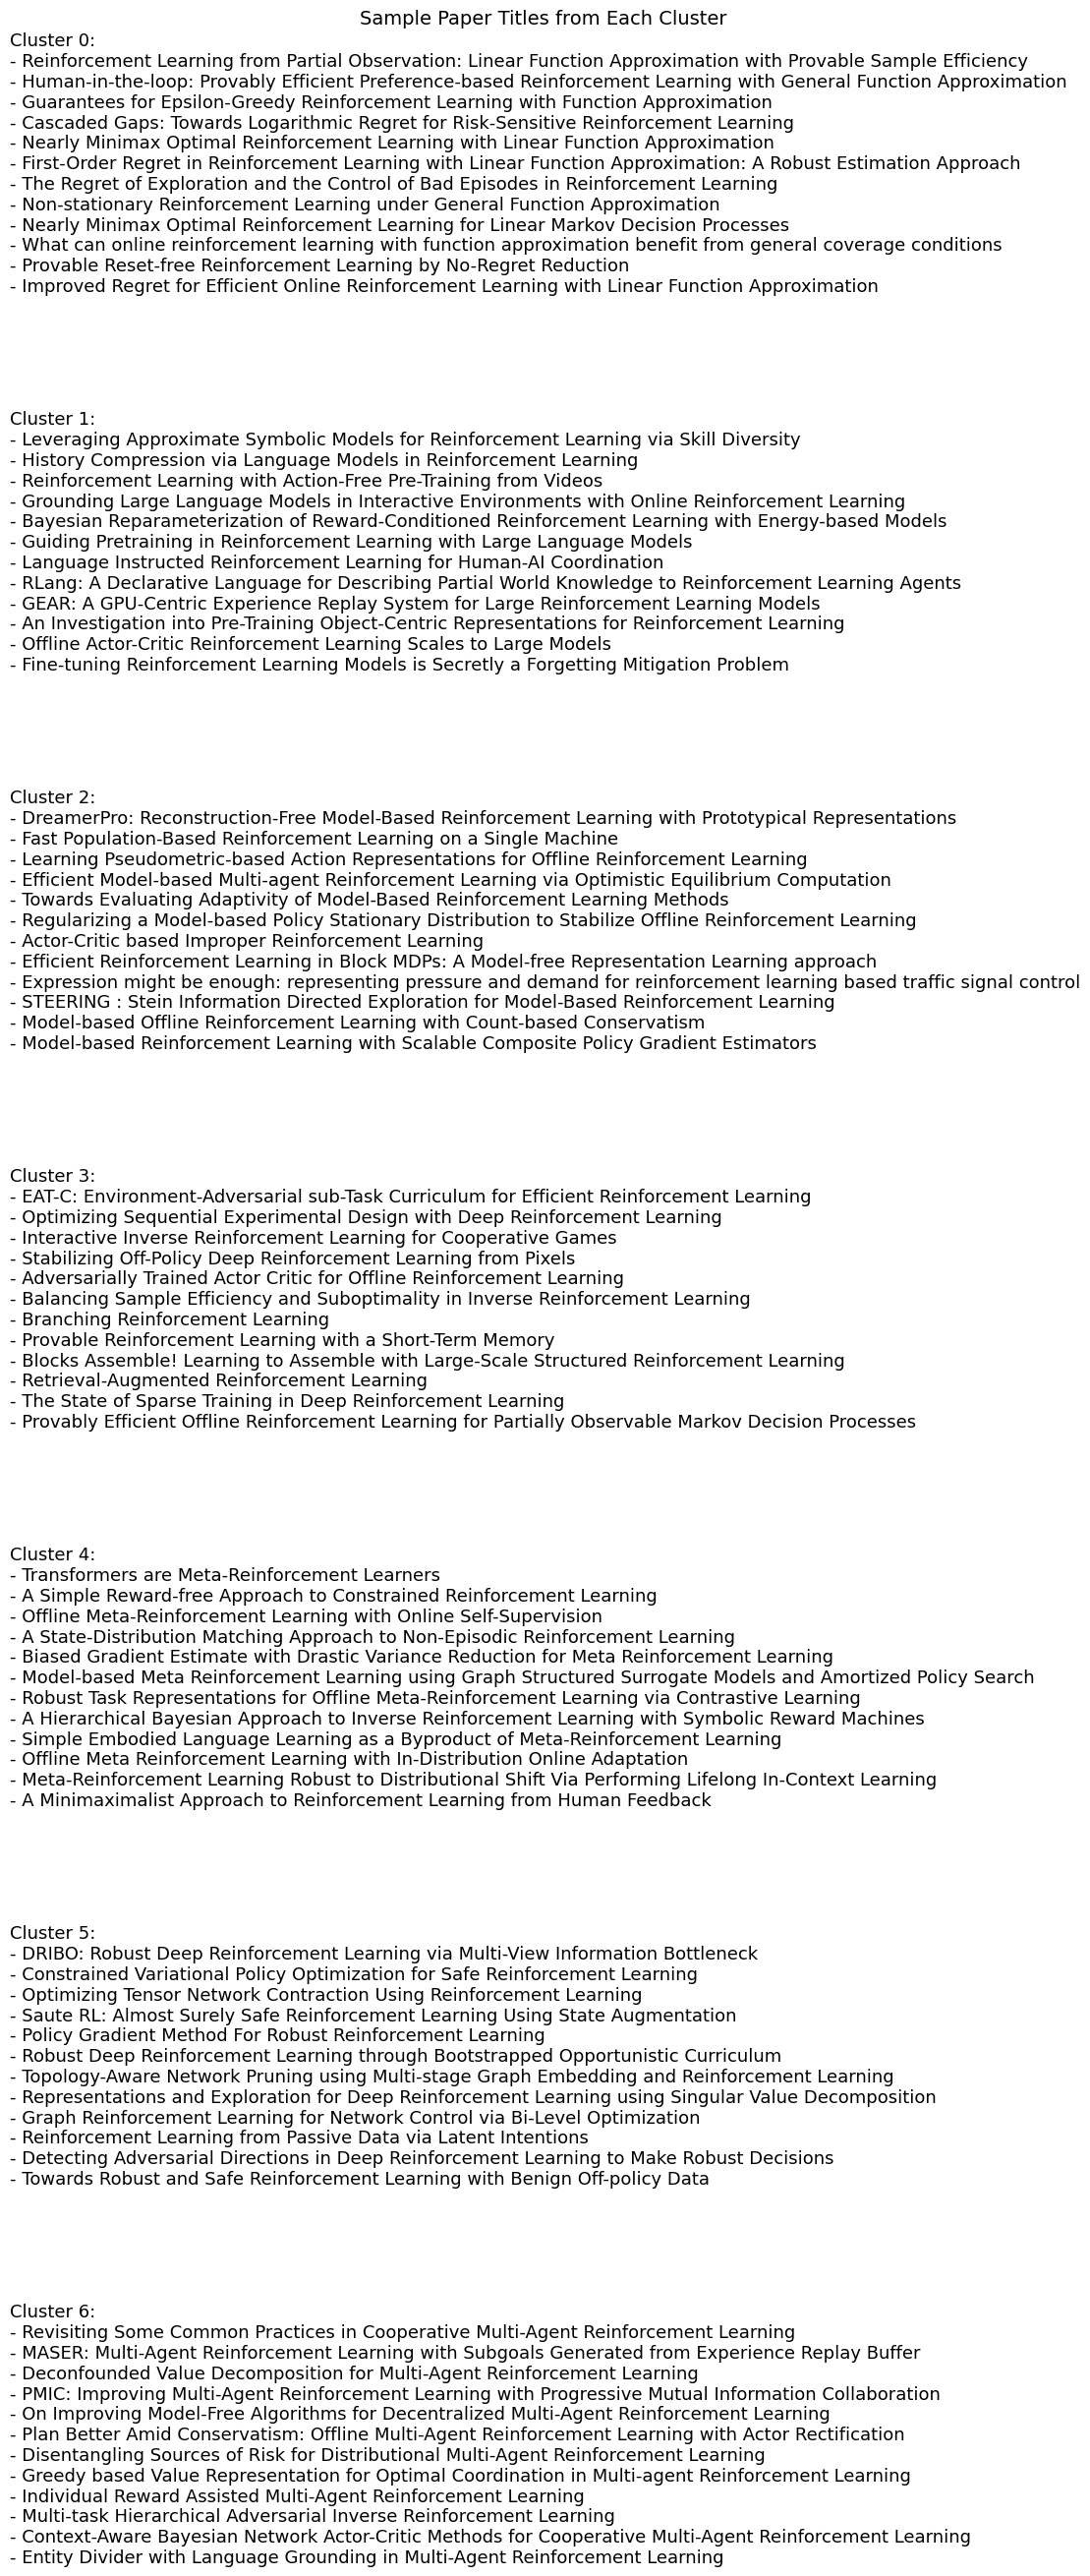

In [8]:
# Re-import required packages after code execution environment reset
import pandas as pd
import matplotlib.pyplot as plt

# Reload the CSV file
file_path = "unified_selective.csv"
df = pd.read_csv(file_path)

# Sample titles by cluster need to be re-generated
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# Extract titles
titles = df['title'].dropna().tolist()

# Convert titles into TF-IDF feature vectors
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(titles)

# Cluster titles using KMeans
num_clusters = 7
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
clusters = kmeans.fit_predict(X)

# Add cluster labels to DataFrame
df['cluster'] = clusters

# Display sample titles using matplotlib
fig, ax = plt.subplots(figsize=(14, 10))

# Plot each cluster's titles
for cluster_id in range(num_clusters):
    cluster_titles = df[df['cluster'] == cluster_id]['title'].head(12).tolist()
    text_block = "\n".join(f"- {title}" for title in cluster_titles)
    ax.text(0, 1 - (cluster_id * 0.5), f"Cluster {cluster_id}:\n{text_block}", 
            fontsize=13, va='top', ha='left', transform=ax.transAxes)

ax.axis('off')
plt.title("Sample Paper Titles from Each Cluster", fontsize=14)
plt.tight_layout()
plt.show()
